# Initialisation du csv dans le Notebook

In [33]:
import pandas as pd

df = pd.read_csv("project_dataset.csv", sep=";")

# Suppression des données dupliquées + Colonnes vides

In [34]:
df = df.drop_duplicates()
for col in [
    "Commentaire annulations",
    "Commentaire retards au départ",
    "Commentaire retards à l'arrivée",
]:
    if col in df.columns:
        df = df.drop(col, axis=1)

cols_gares = ["Gare de départ", "Gare d'arrivée", "Date"]

for col in cols_gares:
    if col in df.columns:
        df[col] = df[col].astype(str).str.strip()

import numpy as np

df[cols_gares] = df[cols_gares].replace(["", "NAN", "NaN", "nan"], np.nan)

df = df.dropna(subset=cols_gares, how="any")

# Suppression des accents

In [35]:
import unicodedata


def clean_accents(text):
    if not isinstance(text, str):
        return text
    nfkd_form = unicodedata.normalize("NFKD", text)
    return "".join([c for c in nfkd_form if not unicodedata.combining(c)]).upper()


df = df.apply(clean_accents)

# Nettoyage des valeurs de Date

In [36]:
def trait_date(cellule):
    s = str(cellule).replace("/", "-").replace(" ", "-")
    pieces = s.split("-")
    annee = ""
    mois = ""
    for p in pieces:
        if len(p) == 4:
            annee = p
        elif len(p) == 2:
            mois = p
        elif len(p) == 1:
            mois = p.zfill(2)
    if annee and mois:
        return f"{annee}-{mois}"
    return cellule


df["Date"] = df["Date"].apply(trait_date)

# Nettoyage des valeurs de Service

In [37]:
def trait_service(ligne):
    if pd.notna(ligne["Service"]) and ligne["Service"] != "":
        return ligne["Service"]
    gares_etranger = [
        "BARCELONA",
        "FRANCFORT",
        "MADRID",
        "ITALIE",
        "LAUSANNE",
        "GENEVE",
        "ZURICH",
        "STUTTGART",
    ]
    depart = str(ligne["Gare de départ"]).upper().strip()
    arrivee = str(ligne["Gare d'arrivée"]).upper().strip()
    for gare in gares_etranger:
        if gare in depart or gare in arrivee:
            return "International"
    return "National"


df["Service"] = df.apply(trait_service, axis=1)

# Nettoyage des valeurs de Départ et D'arrivée

In [38]:
colonnes_gares = ["Gare de départ", "Gare d'arrivée"]
for col in colonnes_gares:
    df[col] = df[col].astype(str)
    df[col] = df[col].str.lower()
    df[col] = df[col].str.strip()
    df[col] = df[col].str.replace("saint", "st")
    df[col] = df[col].str.upper()

# Nettoyage des valeurs à nombres

In [39]:
colonnes = [
    "Durée moyenne du trajet",
    "Nombre de circulations prévues",
    "Nombre de trains annulés",
    "Nombre de trains en retard au départ",
    "Retard moyen des trains en retard au départ",
    "Retard moyen de tous les trains au départ",
    "Nombre de trains en retard à l'arrivée",
    "Retard moyen des trains en retard à l'arrivée",
    "Retard moyen de tous les trains à l'arrivée",
    "Nombre trains en retard > 15min",
    "Nombre trains en retard > 30min",
    "Nombre trains en retard > 60min",
    "Prct retard pour causes externes",
    "Prct retard pour cause infrastructure",
    "Prct retard pour cause gestion trafic",
    "Prct retard pour cause matériel roulant",
    "Prct retard pour cause gestion en gare et réutilisation de matériel",
    "Prct retard pour cause prise en compte voyageurs (affluence, gestions PSH, correspondances)",
    "Retard moyen trains en retard > 15 (si liaison concurrencée par vol)",
]

for col in df.columns:
    if col in colonnes:
        df[col] = df[col].astype(str)
        df[col] = df[col].str.replace(",", ".")
        df[col] = df[col].str.replace("%", "")
        df[col] = df[col].str.replace("min", "")
        df[col] = df[col].str.strip()
        df[col] = df[col].astype(float)
        df[col] = pd.to_numeric(df[col], errors="coerce")
        df[col] = df[col].fillna(0.0).round(2)

# Feature engineering

In [40]:
df["Annee"] = df["Date"].str.split("-").str[0]
df["Mois"] = df["Date"].str.split("-").str[1]
df["Annee"] = pd.to_numeric(df["Annee"], errors="coerce")
df["Mois"] = pd.to_numeric(df["Mois"], errors="coerce")
df["Annee"] = df["Annee"].fillna(0).astype(int)
df["Mois"] = df["Mois"].fillna(0).astype(int).astype(str).str.zfill(2)

# Traitement des valeurs extrêmes

In [41]:
df = df[
    (df["Durée moyenne du trajet"] >= 30)
    & (df["Nombre de circulations prévues"] >= 1)
    & (df["Nombre de trains annulés"] <= 0.30 * df["Nombre de circulations prévues"])
    & (
        df["Nombre de trains en retard au départ"]
        <= df["Nombre de circulations prévues"]
    )
    & (
        df["Nombre de trains en retard à l'arrivée"]
        <= df["Nombre de circulations prévues"]
    )
    & (df["Retard moyen des trains en retard au départ"] >= 0)
    & (df["Retard moyen des trains en retard au départ"] <= 180)
    & (df["Retard moyen de tous les trains au départ"] >= -15)
    & (df["Retard moyen de tous les trains au départ"] <= 60)
    & (df["Retard moyen des trains en retard à l'arrivée"] >= 0)
    & (df["Retard moyen des trains en retard à l'arrivée"] <= 180)
    & (df["Retard moyen de tous les trains à l'arrivée"] >= -20)
    & (df["Retard moyen de tous les trains à l'arrivée"] <= 60)
    & (
        df["Nombre trains en retard > 15min"]
        <= df["Nombre de trains en retard à l'arrivée"]
    )
    & (df["Nombre trains en retard > 30min"] <= df["Nombre trains en retard > 15min"])
    & (df["Nombre trains en retard > 60min"] <= df["Nombre trains en retard > 30min"])
]

# Exportation du CSV

In [42]:
df.to_csv("cleaned_dataset.csv", index=False, sep=";")

# Étape 2 — Visualisation et analyse

In [43]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")

TARGET_COL = "Retard moyen de tous les trains à l'arrivée"

if Path("cleaned_dataset.csv").exists():
    df_clean = pd.read_csv("cleaned_dataset.csv", sep=";")
elif "df" in globals():
    df_clean = df.copy()
else:
    raise FileNotFoundError("cleaned_dataset.csv introuvable et variable `df` absente.")

if TARGET_COL not in df_clean.columns:
    raise KeyError(f"Colonne cible introuvable: {TARGET_COL}")

df_clean["Date_dt"] = pd.to_datetime(
    df_clean["Date"].astype(str) + "-01", errors="coerce"
)
df_clean = df_clean.dropna(subset=["Date_dt"]).sort_values("Date_dt")

display(pd.DataFrame({"n_lignes": [len(df_clean)], "n_colonnes": [df_clean.shape[1]]}))

key_numeric_cols = [
    "Nombre de circulations prévues",
    "Nombre de trains annulés",
    "Nombre de trains en retard au départ",
    "Retard moyen de tous les trains au départ",
    "Nombre de trains en retard à l'arrivée",
    "Retard moyen de tous les trains à l'arrivée",
    "Retard moyen des trains en retard à l'arrivée",
    "Nombre trains en retard > 15min",
    "Nombre trains en retard > 30min",
    "Nombre trains en retard > 60min",
    "Durée moyenne du trajet",
    "Prct retard pour causes externes",
    "Prct retard pour cause infrastructure",
    "Prct retard pour cause gestion trafic",
    "Prct retard pour cause matériel roulant",
    "Prct retard pour cause gestion en gare et réutilisation de matériel",
    "Prct retard pour cause prise en compte voyageurs (affluence, gestions PSH, correspondances)",
]
key_numeric_cols = [c for c in key_numeric_cols if c in df_clean.columns]

if key_numeric_cols:
    display(df_clean[key_numeric_cols].describe().T)

missing_pct = (df_clean.isna().mean() * 100).sort_values(ascending=False)
display(missing_pct.head(10).to_frame("missing_%"))

display(df_clean[[TARGET_COL]].describe().T)

if "Service" in df_clean.columns:
    display(
        df_clean.groupby("Service")[TARGET_COL]
        .agg(["count", "mean", "median", "std", "min", "max"])
        .sort_values("mean", ascending=False)
    )

,n_lignes,n_colonnes
0,9863,26


,count,mean,std,min,25%,50%,75%,max
Nombre de circulations prévues,9863.0,273.526209,181.565111,1.00,153.000,231.00,361.000,1100.00
Nombre de trains annulés,9863.0,6.347055,15.058781,0.00,0.000,2.00,6.000,297.00
Nombre de trains en retard au départ,9863.0,87.382744,90.798784,0.00,21.000,53.00,128.000,1066.00
Retard moyen de tous les trains au départ,9863.0,3.046776,3.385731,-7.69,1.160,2.29,3.920,55.55
Nombre de trains en retard à l'arrivée,9863.0,38.218189,31.444369,0.00,16.000,30.00,52.000,376.00
Retard moyen de tous les trains à l'arrivée,9863.0,6.076236,4.078912,-15.19,3.330,5.30,8.030,36.82
Retard moyen des trains en retard à l'arrivée,9863.0,34.625253,15.411763,0.00,25.400,33.25,42.250,164.39
Nombre trains en retard > 15min,9863.0,27.400385,22.907890,0.00,11.000,22.00,37.000,312.00
Nombre trains en retard > 30min,9863.0,13.206834,12.128127,0.00,5.000,10.00,18.000,202.00
Nombre trains en retard > 60min,9863.0,4.905404,5.626378,0.00,1.000,3.00,7.000,71.00


,missing_%
Date,0.0
Service,0.0
Gare de départ,0.0
Gare d'arrivée,0.0
Durée moyenne du trajet,0.0
Nombre de circulations prévues,0.0
Nombre de trains annulés,0.0
Nombre de trains en retard au départ,0.0
Retard moyen des trains en retard au départ,0.0
Retard moyen de tous les trains au départ,0.0


,count,mean,std,min,25%,50%,75%,max
Retard moyen de tous les trains à l'arrivée,9863.0,6.076236,4.078912,-15.19,3.33,5.3,8.03,36.82


,count,mean,median,std,min,max
Service,,,,,,
International,1209,7.88038,6.98,5.564542,-4.00,33.98
National,8654,5.82419,5.12,3.757801,-15.19,36.82


## Visualisation 1 — Distribution des retards (arrivée)

,count
retard_min,
4,1264
5,1222
3,1172
6,1056
2,788
7,780
8,692
9,532
10,399


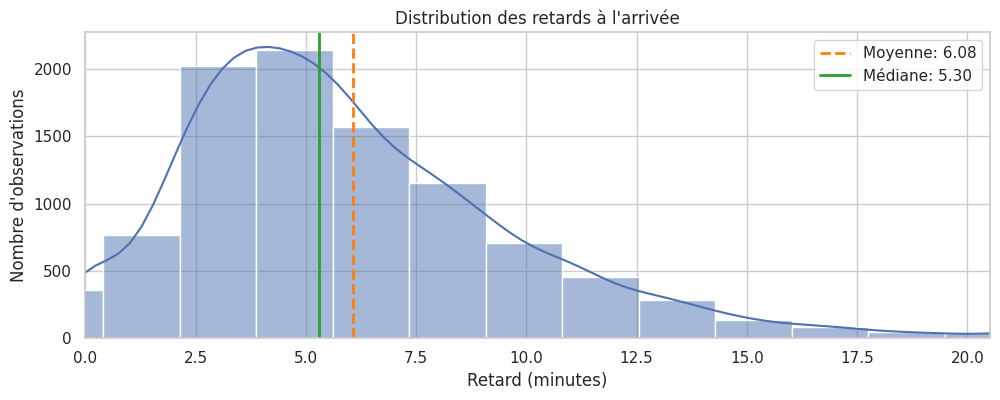

In [44]:
series = df_clean[TARGET_COL].dropna()

common_delays = series.round().astype(int).value_counts().head(10)
display(common_delays.to_frame("count").rename_axis("retard_min"))

q_low, q_high = series.quantile([0.01, 0.99]).tolist()
mean_val = float(series.mean())
median_val = float(series.median())

plt.figure(figsize=(10, 4))
ax = sns.histplot(series, bins=30, kde=True)
ax.axvline(
    mean_val,
    color="tab:orange",
    linestyle="--",
    linewidth=2,
    label=f"Moyenne: {mean_val:.2f}",
)
ax.axvline(
    median_val,
    color="tab:green",
    linestyle="-",
    linewidth=2,
    label=f"Médiane: {median_val:.2f}",
)

ax.set_title("Distribution des retards à l'arrivée")
ax.set_xlabel("Retard (minutes)")
ax.set_ylabel("Nombre d'observations")
ax.set_xlim(q_low, q_high)
ax.legend()
plt.tight_layout(pad=0.6)
plt.show()

**Interprétation**

- Ce graphique montre la forme globale de la distribution des retards à l’arrivée (variable cible `TARGET_COL`).

- Les lignes verticale “Moyenne” (orange) et “Médiane” (verte) aident à juger si la distribution est symétrique ou plutôt tirée par quelques valeurs élevées (asymétrie à droite si moyenne > médiane).

- La limitation de l’axe au 1er–99e percentile rend la masse principale lisible, tout en reconnaissant qu’il existe des cas extrêmes hors champ.

- Le tableau des “retards les plus fréquents” (valeurs arrondies à la minute) met en évidence les durées de retard typiques observées.


## Visualisation 2 — Comparaison par service

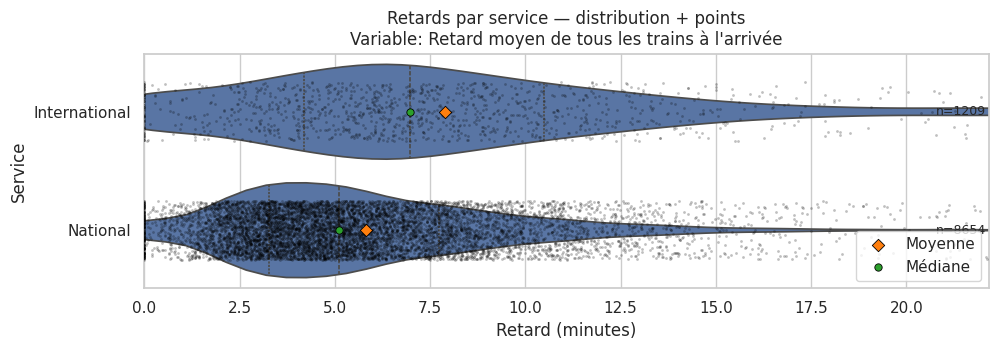

In [45]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")

if "TARGET_COL" not in globals():
    TARGET_COL = "Retard moyen de tous les trains à l'arrivée"

if "df_clean" not in globals():
    if Path("cleaned_dataset.csv").exists():
        df_clean = pd.read_csv("cleaned_dataset.csv", sep=";")
    elif "df" in globals():
        df_clean = df.copy()
    else:
        raise FileNotFoundError(
            "cleaned_dataset.csv introuvable et variable `df` absente."
        )

if TARGET_COL not in df_clean.columns:
    raise KeyError(f"Colonne cible introuvable: {TARGET_COL}")

if "Service" not in df_clean.columns:
    print(
        "Colonne 'Service' absente : impossible de tracer la comparaison par service."
    )
else:
    plot_df = df_clean[["Service", TARGET_COL]].dropna().copy()
    service_stats = (
        plot_df.groupby("Service")[TARGET_COL]
        .agg(n="count", mean="mean", median="median")
        .sort_values("mean", ascending=False)
    )
    services_order = service_stats.index.tolist()
    x_low, x_high = plot_df[TARGET_COL].quantile([0.01, 0.99]).tolist()
    x_pad = (x_high - x_low) * 0.08
    plt.figure(figsize=(10, max(3.5, 0.45 * len(services_order))))
    ax = sns.violinplot(
        data=plot_df,
        y="Service",
        x=TARGET_COL,
        order=services_order,
        cut=0,
        inner="quartile",
        density_norm="width",
    )
    sns.stripplot(
        data=plot_df,
        y="Service",
        x=TARGET_COL,
        order=services_order,
        color="black",
        alpha=0.25,
        size=2,
        jitter=0.25,
        ax=ax,
    )
    y_pos = np.arange(len(services_order))
    ax.scatter(
        service_stats["mean"].to_numpy(),
        y_pos,
        marker="D",
        s=40,
        color="tab:orange",
        edgecolor="black",
        linewidth=0.6,
        zorder=5,
        label="Moyenne",
    )
    ax.scatter(
        service_stats["median"].to_numpy(),
        y_pos,
        marker="o",
        s=28,
        color="tab:green",
        edgecolor="black",
        linewidth=0.6,
        zorder=5,
        label="Médiane",
    )
    ax.set_xlim(x_low, x_high + x_pad)
    x_text = x_high + x_pad * 0.15
    for i, svc in enumerate(services_order):
        ax.text(
            x_text, i, f"n={int(service_stats.loc[svc, 'n'])}", va="center", fontsize=9
        )
    ax.set_title(f"Retards par service — distribution + points\nVariable: {TARGET_COL}")
    ax.set_xlabel("Retard (minutes)")
    ax.set_ylabel("Service")
    ax.legend(loc="lower right")
    plt.tight_layout(pad=0.6)
    plt.show()

**Interprétation**

- Les services sont triés du plus grand au plus petit retard moyen.

- La forme du violon montre où se concentrent les retards (densité) et les traits internes donnent les quartiles ; les points noirs représentent les observations.

- Le diamant (moyenne) et le point vert (médiane) résument chaque service : si la moyenne est nettement au-dessus de la médiane, quelques gros retards tirent la moyenne vers le haut.

- `n` indique le nombre d’observations par service (comparaison plus fiable quand `n` est grand).

- L’axe $x$ est limité au 1%–99% pour la lisibilité : les valeurs extrêmes existent mais sont hors champ.


## Visualisation 3 — Tendance temporelle

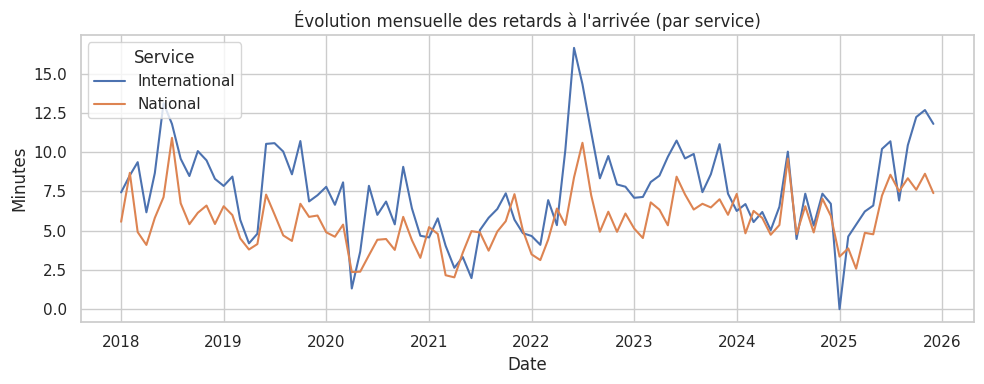

In [46]:
if "Service" in df_clean.columns:
    trend_df = (
        df_clean.groupby(["Date_dt", "Service"], as_index=False)[TARGET_COL]
        .mean()
        .sort_values("Date_dt")
    )

    plt.figure(figsize=(10, 4))
    sns.lineplot(data=trend_df, x="Date_dt", y=TARGET_COL, hue="Service")
    plt.title("Évolution mensuelle des retards à l'arrivée (par service)")
    plt.xlabel("Date")
    plt.ylabel("Minutes")
    plt.tight_layout()
    plt.show()
else:
    trend_df = (
        df_clean.groupby(["Date_dt"], as_index=False)[TARGET_COL]
        .mean()
        .sort_values("Date_dt")
    )

    plt.figure(figsize=(10, 4))
    sns.lineplot(data=trend_df, x="Date_dt", y=TARGET_COL)
    plt.title("Évolution mensuelle des retards à l'arrivée")
    plt.xlabel("Date")
    plt.ylabel("Minutes")
    plt.tight_layout()
    plt.show()

**Interprétation**

- Cette courbe montre l’évolution *mensuelle* du retard **moyen** à l’arrivée (agrégation par `mean()` sur `Date_dt`, et aussi par `Service` si la colonne existe).

- Si `Service` est présent, chaque ligne correspond à un service : des courbes qui montent/descendent ensemble suggèrent un effet “global” (période), alors que des écarts marqués indiquent des comportements spécifiques à certains services.

- Les pics/creux correspondent à des mois où la moyenne change fortement ; comme on regarde une moyenne agrégée, il est utile (si besoin) de compléter par une analyse de dispersion sur ces mois pour vérifier si c’est un décalage général ou quelques valeurs extrêmes.


## Visualisation 4 — Comparaison par liaisons (gares)

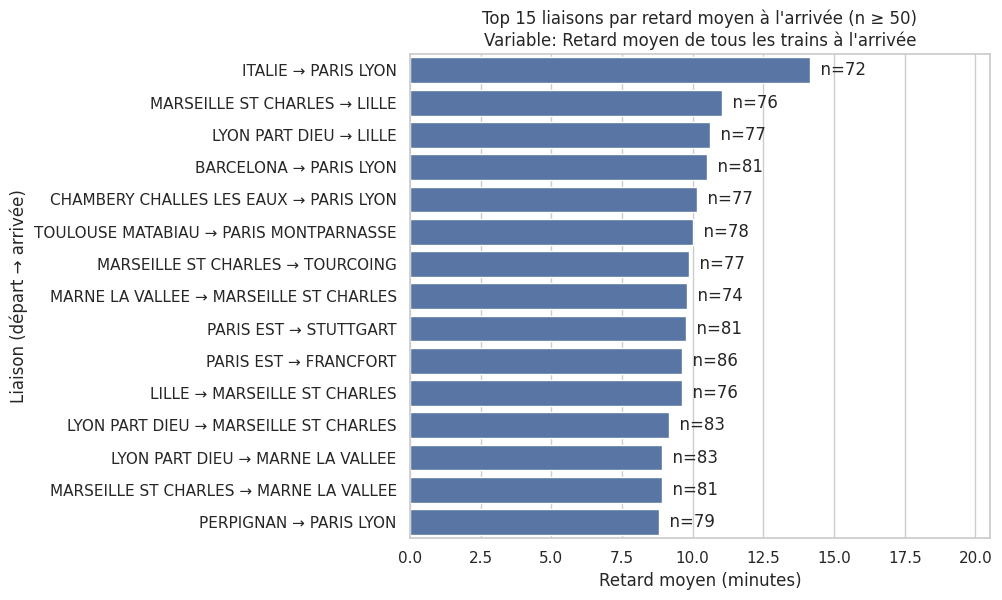

In [47]:
required_cols = {"Gare de départ", "Gare d'arrivée", TARGET_COL}
if not required_cols.issubset(df_clean.columns):
    print(
        f"Colonnes manquantes pour l'analyse par liaisons: {sorted(required_cols - set(df_clean.columns))}"
    )
else:
    routes = df_clean[["Gare de départ", "Gare d'arrivée", TARGET_COL]].dropna().copy()
    routes["Route"] = (
        routes["Gare de départ"].astype(str)
        + " → "
        + routes["Gare d'arrivée"].astype(str)
    )

    route_stats = (
        routes.groupby("Route")[TARGET_COL]
        .agg(count="count", mean="mean", median="median")
        .sort_values("count", ascending=False)
    )

    MIN_N = 50
    route_stats_f = route_stats[route_stats["count"] >= MIN_N].sort_values(
        "mean", ascending=False
    )

    if route_stats_f.empty:
        print(f"Aucune liaison avec n >= {MIN_N} (après filtrage).")
    else:
        top_k = 15
        top_routes = route_stats_f.head(top_k).reset_index()

        y_low, y_high = routes[TARGET_COL].quantile([0.01, 0.99]).tolist()

        plt.figure(figsize=(10, 6))
        ax = sns.barplot(data=top_routes, y="Route", x="mean", orient="h")
        ax.set_title(
            f"Top {top_k} liaisons par retard moyen à l'arrivée (n ≥ {MIN_N})\nVariable: {TARGET_COL}"
        )
        ax.set_xlabel("Retard moyen (minutes)")
        ax.set_ylabel("Liaison (départ → arrivée)")
        ax.set_xlim(y_low, y_high)

        for i, row in top_routes.iterrows():
            ax.text(float(row["mean"]), i, f"  n={int(row['count'])}", va="center")

        plt.tight_layout(pad=0.6)
        plt.show()

**Interprétation**

- Ce graphique classe les liaisons (gare de départ → gare d’arrivée) par **retard moyen** à l’arrivée : seules les liaisons avec un effectif suffisant sont gardées ($n \geq 50$), puis on affiche le **Top 15** par moyenne.

- L’annotation `n` à droite de chaque barre indique le nombre d’observations utilisées pour calculer la moyenne : c’est indispensable pour juger la fiabilité de la comparaison entre liaisons.

- L’axe $x$ est limité aux quantiles 1%–99% des retards (sur l’ensemble des trajets) pour garder une échelle lisible ; les cas extrêmes existent toujours mais ne sont pas représentés dans l’échelle.

- Comme on compare des moyennes, deux liaisons peuvent avoir une moyenne proche mais des dispersions très différentes : si tu veux caractériser la variabilité, il faudrait ajouter un graphique de distribution (boxplot/violon) sur ces mêmes liaisons.
